# Módulo 4 — Compresión de la información de imagen

**Objetivo.** Evaluar algoritmos de compresión con y sin pérdida sobre los frames del registro y la ROI segmentada.

- **Sin pérdida:** Huffman y Run-Length Encoding (RLE) en dos direcciones de recorrido (horizontal y vertical).
- **Con pérdida:** JPEG con factor de calidad Q = 90, 50, 10 y 5.

Para cada método se calcula la tasa de compresión (bytes originales / bytes comprimidos), PSNR y SSIM. Además se analiza a partir de qué Q aparecen artefactos de bloque, si los artefactos son mayores en el borde pupilar o en las regiones uniformes, y si la compresión cambia el diámetro pupilar medido en el Módulo 3.

Las funciones están en `pupiltrack/compression.py` y también se ejecutan en `run_pipeline.py` (salidas `compresion_metodos.csv` y `compresion_diametro.csv`).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from pupiltrack.config import cargar_config
from pupiltrack import acquisition as acq, temporal, compression as comp

VIDEO = "data/A1.mov"      # registro A1 (contracción)
TIPO = "A"

cfg = cargar_config(RAIZ / "config.yaml")
cfg["video"]["path"] = str(RAIZ / VIDEO)
cfg["video"]["tipo"] = TIPO
pd.set_option("display.width", 200)

## 1. Frame original y ROI segmentada

Se procesa el video con el pipeline (Módulos 0–3) para obtener la segmentación de la pupila en cada frame. Se toma como frame representativo un frame válido de la mitad del registro, y sobre él se definen:

- el **frame completo** en escala de grises,
- la **ROI del ojo** (recorte alrededor de la pupila),
- la **máscara binaria de la pupila** segmentada (watershed del Módulo 2/3).

Frame 747 (t = 12.46 s) | diámetro = 55.8 px
Frame: 900x506 px | ROI: 223x223 px


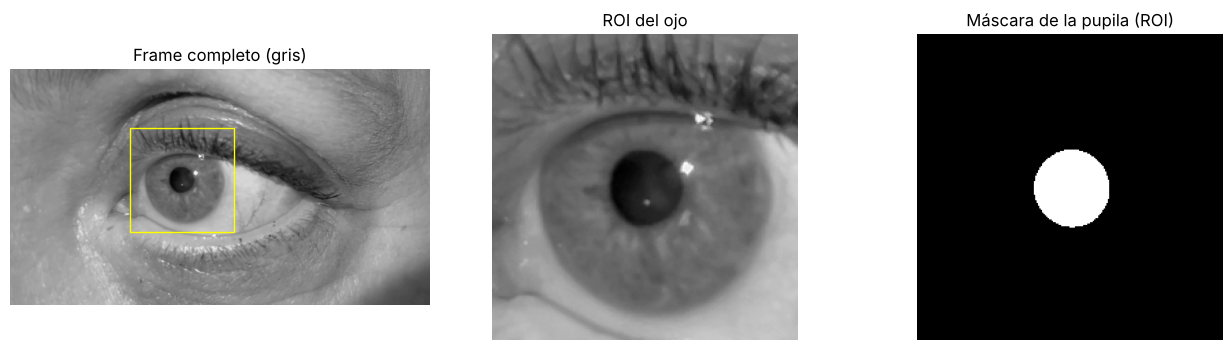

In [2]:
df, fps, _ = temporal.procesar_video(cfg)
frames, _ = acq.extraer_frames(cfg["video"]["path"])

validos = df.index[df["valido"]]
i_rep = validos[abs(validos - len(df) // 2).argmin()]
fila = df.loc[i_rep]
gris = cv2.cvtColor(frames[i_rep], cv2.COLOR_BGR2GRAY)
mascara = comp.mascara_pupila_en_frame(frames[i_rep], fila["centroide_x"], fila["centroide_y"], fila["diametro_px"])
roi, (x0, y0) = comp.roi_ojo(gris, fila["centroide_x"], fila["centroide_y"], fila["diametro_px"])
mascara_roi = mascara[y0:y0 + roi.shape[0], x0:x0 + roi.shape[1]]

print(f"Frame {i_rep} (t = {fila['tiempo_s']:.2f} s) | diámetro = {fila['diametro_px']:.1f} px")
print(f"Frame: {gris.shape[1]}x{gris.shape[0]} px | ROI: {roi.shape[1]}x{roi.shape[0]} px")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].imshow(gris, cmap="gray"); ax[0].set_title("Frame completo (gris)")
ax[0].add_patch(plt.Rectangle((x0, y0), roi.shape[1], roi.shape[0], fill=False, ec="yellow"))
ax[1].imshow(roi, cmap="gray"); ax[1].set_title("ROI del ojo")
ax[2].imshow(mascara_roi, cmap="gray"); ax[2].set_title("Máscara de la pupila (ROI)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 2. Compresión sin pérdida: Huffman y RLE

- **Huffman** asigna códigos más cortos a los niveles de gris más frecuentes. Su límite teórico es la **entropía** de la imagen (bits/píxel): la tasa máxima esperable es ≈ 8 / H.
- **RLE** guarda pares (valor, longitud de la corrida). Rinde cuando hay corridas largas de píxeles iguales, y se prueba recorriendo la imagen por filas (horizontal) y por columnas (vertical). Cada par ocupa 2 bytes (corridas de hasta 255).

Primero se verifica que ambos métodos sean realmente **sin pérdida** (la imagen decodificada es idéntica a la original).

In [3]:
bits, tabla_h, forma = comp.huffman_codificar(roi)
assert np.array_equal(comp.huffman_decodificar(bits, tabla_h, forma), roi)
for d in ("horizontal", "vertical"):
    assert np.array_equal(comp.rle_decodificar(comp.rle_codificar(roi, d), roi.shape, d), roi)
print("Huffman y RLE (H y V): decodificación idéntica al original -> sin pérdida")

res_frame = comp.evaluar_compresion(gris, mascara)
res_roi = comp.evaluar_compresion(roi, mascara_roi)
cols = ["objeto", "metodo", "bytes_original", "bytes_comprimido", "ratio", "entropia_bits"]
sin_perdida = pd.concat({"frame completo": res_frame, "ROI del ojo": res_roi})
sin_perdida = sin_perdida[sin_perdida["metodo"].str.match("Huffman|RLE")][cols]
sin_perdida

Huffman y RLE (H y V): decodificación idéntica al original -> sin pérdida


objeto          metodo  bytes_original  bytes_comprimido    ratio  entropia_bits
frame completo 0    frame         Huffman          455400            395548    1.151          6.916
               1    frame  RLE horizontal          455400            672502    0.677            NaN
               2    frame    RLE vertical          455400            691242    0.659            NaN
               3  mascara         Huffman          455400             56929    7.999            NaN
               4  mascara  RLE horizontal          455400              3742  121.700            NaN
               5  mascara    RLE vertical          455400              3686  123.549            NaN
ROI del ojo    0    frame         Huffman           49729             44488    1.118          7.046
               1    frame  RLE horizontal           49729             80484    0.618            NaN
               2    frame    RLE vertical           49729             81718    0.609            NaN
               3  mascara         Huffman           49729              6221    7.994            NaN
               4  mascara  RLE horizontal           49729               520   95.633            NaN
               5  mascara    RLE vertical           49729               514   96.749            NaN

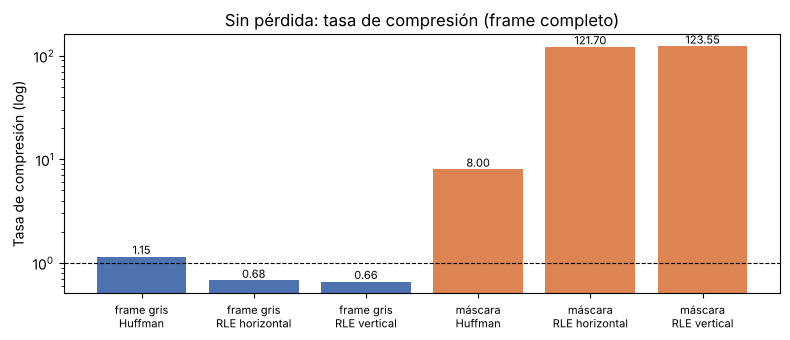

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
t = res_frame[res_frame["metodo"].str.match("Huffman|RLE")]
etiquetas = [f"{o}\n{m}" for o, m in zip(t["objeto"].replace({"frame": "frame gris", "mascara": "máscara"}), t["metodo"])]
barras = ax.bar(etiquetas, t["ratio"], color=["#4C72B0"] * 3 + ["#DD8452"] * 3)
ax.axhline(1, c="k", lw=0.8, ls="--"); ax.set_yscale("log"); ax.set_ylabel("Tasa de compresión (log)")
ax.bar_label(barras, fmt="%.2f", fontsize=8)
ax.set_title("Sin pérdida: tasa de compresión (frame completo)")
plt.xticks(fontsize=8); plt.tight_layout(); plt.show()

## 3. Compresión con pérdida: JPEG (Q = 90, 50, 10, 5)

Para cada Q se comprime y descomprime el frame, y se mide la tasa de compresión, el PSNR y el SSIM respecto del original. Los métodos sin pérdida tienen PSNR = ∞ y SSIM = 1 por definición.

In [5]:
jpeg_tab = res_frame[res_frame["metodo"].str.startswith("JPEG")][["metodo", "bytes_comprimido", "ratio", "psnr_db", "ssim", "blocking"]]
jpeg_tab

,metodo,bytes_comprimido,ratio,psnr_db,ssim,blocking
7,JPEG Q=90,61134,7.449,47.82,0.9897,1.260
8,JPEG Q=50,23094,19.719,41.96,0.9649,2.038
9,JPEG Q=10,8529,53.394,34.14,0.8451,6.644
10,JPEG Q=5,6679,68.184,30.52,0.7642,15.169


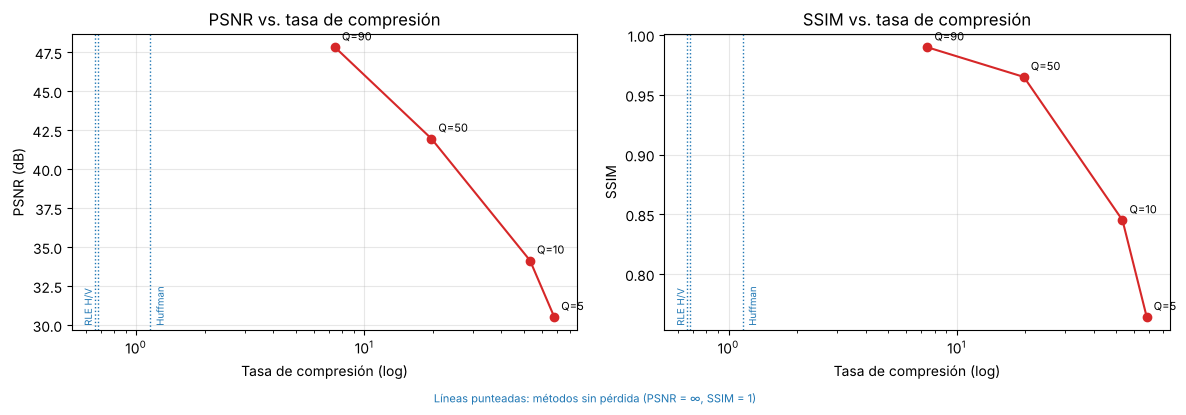

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, met, lab in [(ax[0], "psnr_db", "PSNR (dB)"), (ax[1], "ssim", "SSIM")]:
    a.plot(jpeg_tab["ratio"], jpeg_tab[met], "o-", c="tab:red", label="JPEG")
    for _, r in jpeg_tab.iterrows():
        a.annotate(r["metodo"].replace("JPEG ", ""), (r["ratio"], r[met]), textcoords="offset points", xytext=(5, 5), fontsize=8)
    sp = res_frame[res_frame["objeto"].eq("frame") & res_frame["metodo"].str.match("Huffman|RLE")]
    for _, r in sp.iterrows():
        a.axvline(r["ratio"], ls=":", c="tab:blue", lw=1)
    a.annotate("Huffman", (sp["ratio"].iloc[0], a.get_ylim()[0]), rotation=90, fontsize=7, color="tab:blue", xytext=(3, 5), textcoords="offset points")
    a.annotate("RLE H/V", (sp["ratio"].iloc[1:].min(), a.get_ylim()[0]), rotation=90, fontsize=7, color="tab:blue", xytext=(-9, 5), textcoords="offset points")
    a.set_xscale("log"); a.set_xlabel("Tasa de compresión (log)"); a.set_ylabel(lab); a.grid(alpha=.3)
ax[0].set_title("PSNR vs. tasa de compresión"); ax[1].set_title("SSIM vs. tasa de compresión")
fig.text(0.5, -0.02, "Líneas punteadas: métodos sin pérdida (PSNR = ∞, SSIM = 1)", ha="center", fontsize=8, color="tab:blue")
plt.tight_layout(); plt.show()

## 4. Observación visual: artefactos de bloque

JPEG trabaja con bloques de 8×8 píxeles. Al bajar Q, la cuantización de la DCT hace visibles los bordes de esa grilla (*blocking artifacts*). Además de la inspección visual, se calcula un **índice de blocking**: la discontinuidad media en los bordes de bloque dividida por la discontinuidad media dentro de los bloques (≈ 1 sin artefactos; > 1 cuando aparece la grilla).

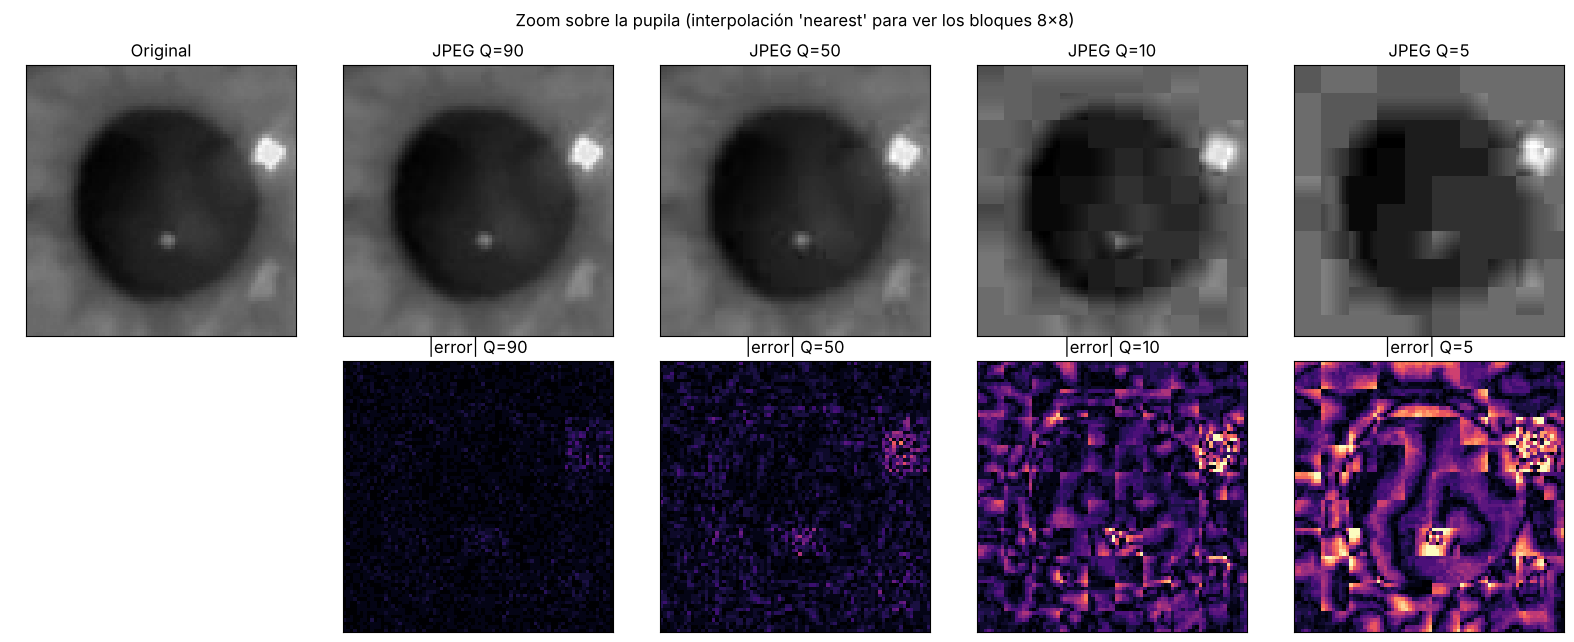

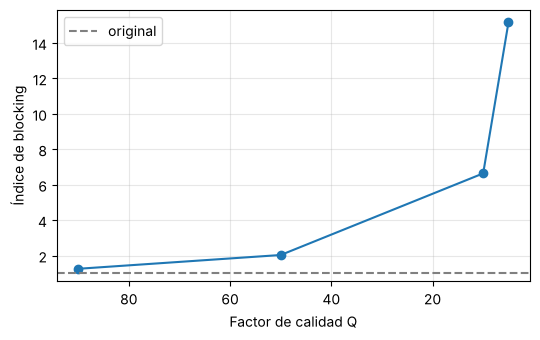

In [7]:
qs = comp.CALIDADES_JPEG
fig, ax = plt.subplots(2, len(qs) + 1, figsize=(16, 6.5))
cy, cx = roi.shape[0] // 2, roi.shape[1] // 2
lado = int(fila["diametro_px"] * 1.4)
zoom = lambda im: im[cy - lado // 2: cy + lado // 2, cx - lado // 2: cx + lado // 2]
ax[0, 0].imshow(zoom(roi), cmap="gray", vmin=0, vmax=255, interpolation="nearest"); ax[0, 0].set_title("Original")
ax[1, 0].axis("off")
for k, q in enumerate(qs, start=1):
    rec, _ = comp.jpeg(roi, q)
    ax[0, k].imshow(zoom(rec), cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax[0, k].set_title(f"JPEG Q={q}")
    err = np.abs(rec.astype(float) - roi)
    ax[1, k].imshow(zoom(err), cmap="magma", vmin=0, vmax=25, interpolation="nearest")
    ax[1, k].set_title(f"|error| Q={q}")
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.suptitle("Zoom sobre la pupila (interpolación 'nearest' para ver los bloques 8x8)")
plt.tight_layout(); plt.show()

fig, a = plt.subplots(figsize=(5.5, 3.5))
bl = res_frame[res_frame["metodo"].str.startswith("JPEG")]
a.plot([int(m.split("=")[1]) for m in bl["metodo"]], bl["blocking"], "o-")
a.axhline(res_frame.loc[res_frame["metodo"] == "sin comprimir", "blocking"].iloc[0], ls="--", c="gray", label="original")
a.invert_xaxis(); a.set_xlabel("Factor de calidad Q"); a.set_ylabel("Índice de blocking"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. ¿Dónde son más notorios los artefactos: borde pupilar o regiones uniformes?

Se compara el error absoluto medio de JPEG en dos regiones del frame:

- **Borde pupilar:** franja de ±3 px alrededor del contorno de la pupila segmentada (transición nítida pupila/iris).
- **Región uniforme:** píxeles alejados de la pupila con gradiente bajo (iris y esclerótica lisos, percentil 30 del gradiente).

,metodo,error_borde_pupila,error_region_uniforme,borde / uniforme
7,JPEG Q=90,0.898,0.583,1.54
8,JPEG Q=50,2.073,1.201,1.73
9,JPEG Q=10,5.477,3.088,1.77
10,JPEG Q=5,8.430,5.157,1.63


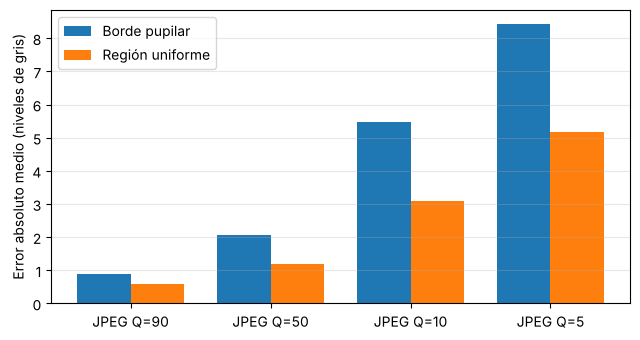

In [8]:
reg = jpeg_tab[["metodo"]].join(res_frame[["error_borde_pupila", "error_region_uniforme"]])
reg["borde / uniforme"] = (reg["error_borde_pupila"] / reg["error_region_uniforme"]).round(2)
display(reg)

fig, a = plt.subplots(figsize=(6.5, 3.5))
x = np.arange(len(reg)); w = 0.38
a.bar(x - w / 2, reg["error_borde_pupila"], w, label="Borde pupilar")
a.bar(x + w / 2, reg["error_region_uniforme"], w, label="Región uniforme")
a.set_xticks(x, reg["metodo"]); a.set_ylabel("Error absoluto medio (niveles de gris)"); a.legend(); a.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

## 6. ¿La compresión a Q = 50/10 cambia el diámetro pupilar estimado (Módulo 3)?

Se eligen 30 frames válidos repartidos a lo largo del registro. En cada uno se mide el diámetro con la **misma función del pipeline** (watershed + elipse sobre el borde visible), sobre el frame original y sobre el mismo frame comprimido con JPEG a cada Q, partiendo del mismo centro.

,calidad_jpeg,frames,diametro_original_medio_px,error_medio_px,error_abs_medio_px,error_abs_medio_pct,error_abs_max_px
0,90,30,61.04,-0.033,0.114,0.19,0.612
1,50,30,61.04,0.104,0.163,0.27,0.676
2,10,30,61.04,0.579,0.845,1.38,3.780
3,5,30,61.04,1.696,1.696,2.78,6.605


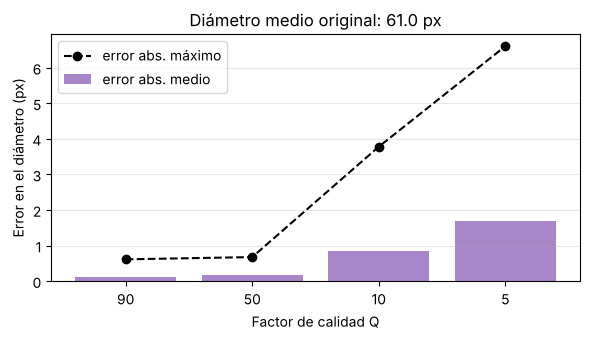

In [9]:
efecto = comp.efecto_en_diametro(frames, df, comp.medir_diametro, n=30)
display(efecto)

fig, a = plt.subplots(figsize=(6, 3.5))
a.bar(efecto["calidad_jpeg"].astype(str), efecto["error_abs_medio_px"], yerr=None, color="tab:purple", alpha=.8, label="error abs. medio")
a.plot(efecto["calidad_jpeg"].astype(str), efecto["error_abs_max_px"], "ko--", label="error abs. máximo")
a.set_xlabel("Factor de calidad Q"); a.set_ylabel("Error en el diámetro (px)"); a.legend(); a.grid(axis="y", alpha=.3)
a.set_title(f"Diámetro medio original: {efecto['diametro_original_medio_px'].iloc[0]:.1f} px")
plt.tight_layout(); plt.show()

## 7. Conclusiones

Resultados sobre el registro **A1** (frame 747, 900×506 px; ROI del ojo de 223×223 px).

**Sin pérdida (Huffman y RLE)**
- **Huffman** comprime el frame en gris solo **1,15:1**. La entropía es de 6,9 bits/píxel, así que la cota teórica es 8 / 6,9 ≈ 1,16: Huffman llega prácticamente al límite. La imagen natural tiene muchos niveles de gris con frecuencias parecidas, y no hay mucho para ganar codificando símbolos aislados.
- **RLE expande el frame en gris** (tasa 0,66–0,68, es decir, el archivo queda más grande). En una imagen con ruido y gradientes casi no hay dos píxeles vecinos iguales, así que se gastan 2 bytes por cada corrida de longitud 1. La dirección de recorrido casi no cambia el resultado (horizontal 0,68 y vertical 0,66).
- **Sobre la ROI segmentada (máscara binaria) el panorama se invierte**: RLE logra **≈ 122:1** en las dos direcciones, porque la máscara está formada por pocas corridas largas de 0 y de 1. Horizontal y vertical dan casi lo mismo (121,7 y 123,5) porque la pupila es aproximadamente circular. Huffman, en cambio, queda limitado a **8:1**: con dos símbolos no puede bajar de 1 bit por píxel.

**Con pérdida (JPEG)**
- La tasa crece de **7,4:1 (Q=90)** a **68:1 (Q=5)**, mientras el PSNR cae de **47,8 a 30,5 dB** y el SSIM de **0,990 a 0,764**. Q=50 es un buen compromiso: **19,7:1** con **42 dB** y SSIM de **0,965**.
- **Artefactos de bloque:** con Q=90 y Q=50 no se ven a simple vista. **Aparecen claramente a partir de Q=10**: la grilla de 8×8 es evidente dentro de la pupila y en el iris, y con Q=5 la pupila queda formada por bloques. El índice de blocking lo confirma: 1,03 en el original, 1,26 con Q=90, 2,04 con Q=50, **6,6 con Q=10** y **15,2 con Q=5**.
- **¿Borde nítido o región uniforme?** El error es **entre 1,5 y 1,8 veces mayor en el borde pupilar** que en las regiones uniformes del iris y la esclerótica, para todos los Q. JPEG descarta primero las frecuencias espaciales altas, y el borde nítido pupila/iris es justamente donde está ese contenido de alta frecuencia (además del reflejo corneal). En las zonas uniformes el artefacto visible es otro: los escalones planos entre bloques, que se notan a Q bajos.

**Efecto sobre el diámetro pupilar (Módulo 3)**
- **Q=50 no cambia el diámetro en forma apreciable**: error absoluto medio de **0,16 px (0,27 %)**, con un máximo de 0,7 px. Es menor que el ruido propio de la medición frame a frame.
- **Q=10 empieza a afectarlo**: error medio de **0,85 px (1,4 %)**, con un máximo de **3,8 px**, y un sesgo positivo (+0,6 px): los bloques desdibujan el borde y la pupila se mide algo más grande.
- Con Q=5 el sesgo llega a +1,7 px (2,8 %) y el máximo a 6,6 px.
- Por lo tanto, para almacenar o transmitir los registros se puede usar JPEG hasta **Q ≈ 50** sin alterar los parámetros fisiológicos. Por debajo de Q ≈ 10, la compresión introduce un error sistemático en el diámetro que afectaría la amplitud de la respuesta.